<a href="https://colab.research.google.com/github/english075social/Clase80/blob/main/Clasificaci%C3%B3n_cultivos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🌱 Vista previa de los datos agrícolas:
   ph_suelo    humedad tipo_suelo  temperatura  precipitacion  horas_sol  \
0  6.249080  42.584086  Arcilloso    17.782324     730.569196   7.210122   
1  7.401429  66.567732    Arenoso    17.015892    1330.642518   6.654447   
2  6.963988  67.031756    Arenoso    20.120311     620.338762   7.243888   
3  6.697317  71.871495  Arcilloso    29.521912     546.945357   8.346952   
4  5.812037  76.304567    Arenoso    26.859258     884.090611   5.728783   

  tipo_de_cultivo  
0           Arroz  
1            Maíz  
2           Trigo  
3            Maíz  
4            Maíz   

📊 Precisión Árbol de Decisión : 38.33%
📊 Precisión Random Forest     : 35.00%

📋 Reporte de clasificación detallado (Random Forest):
              precision    recall  f1-score   support

       Arroz       0.18      0.18      0.18        17
        Maíz       0.38      0.52      0.44        21
       Trigo       0.50      0.32      0.39        22

    accuracy                   

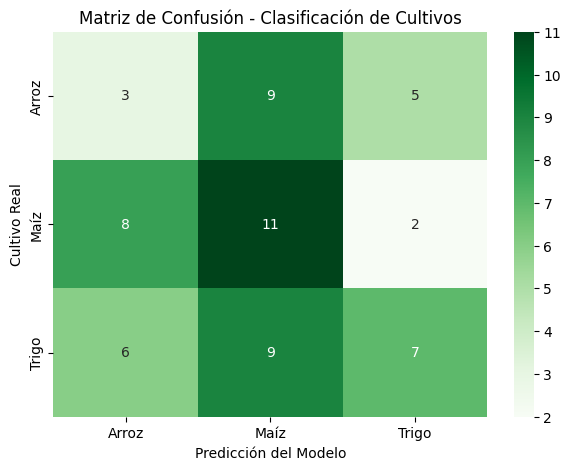

🌾 Importancia de variables ambientales para AgroTech Verde:
  • ph_suelo              : 18.49% de relevancia
  • humedad               : 20.19% de relevancia
  • temperatura           : 19.00% de relevancia
  • precipitacion         : 18.32% de relevancia
  • horas_sol             : 18.53% de relevancia
  • tipo_suelo_codificado : 5.47% de relevancia


In [1]:
# ==============================================================================
# PROYECTO 3: CLASIFICACIÓN MULTICLASE DE CULTIVOS AGRÍCOLAS (AGROTECH VERDE)
# Autores: Luis - Karen - Milena | Fundación Somos F5
# ==============================================================================

# 'import' es la palabra clave para CARGAR librerías externas con herramientas especializadas.
# 'pandas' es la librería principal para manejar tablas de datos (DataFrames).
# 'as pd' nos da un apodo corto ('pd') para no escribir 'pandas' cada vez.
import pandas as pd

# 'numpy' es la librería para realizar operaciones numéricas avanzadas a alta velocidad.
import numpy as np

# 'matplotlib.pyplot' es la librería gráfica estándar para dibujar diagramas y figuras.
import matplotlib.pyplot as plt

# 'seaborn' es una librería basada en matplotlib que genera gráficos estadísticos más atractivos.
# 'as sns' es el apodo corto estándar para seaborn.
import seaborn as sns

# 'from' especifica el módulo exacto del cual queremos extraer funciones en scikit-learn.
# 'train_test_split' separa los datos en grupo de estudio y grupo de examen final.
from sklearn.model_selection import train_test_split

# 'StandardScaler' normaliza los números para que todas las variables tengan la misma escala.
# 'LabelEncoder' convierte texto (ej: tipos de suelo) en números comprensibles para la máquina.
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Cargamos dos algoritmos de clasificación multiclase: Árbol de Decisión y Random Forest.
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Cargamos herramientas de evaluación: precisión y matriz de confusión.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# ------------------------------------------------------------------------------
# 1. GENERACIÓN Y EXPLORACIÓN DE DATOS SIMULADOS
# ------------------------------------------------------------------------------

# 'np.random.seed' fija la semilla aleatoria para que los resultados sean 100% reproducibles.
np.random.seed(42)

# Definimos la cantidad de parcelas agrícolas de muestra para el estudio.
numero_muestras = 300

# Creamos un diccionario con datos aleatorios que simulan el entorno agrícola.
datos_agricolas = {
    "ph_suelo": np.random.uniform(5.5, 7.5, numero_muestras),
    "humedad": np.random.uniform(40.0, 90.0, numero_muestras),
    "tipo_suelo": np.random.choice(["Arcilloso", "Arenoso", "Limoso"], numero_muestras),
    "temperatura": np.random.uniform(15.0, 35.0, numero_muestras),
    "precipitacion": np.random.uniform(500.0, 1500.0, numero_muestras),
    "horas_sol": np.random.uniform(5.0, 10.0, numero_muestras),
    "tipo_de_cultivo": np.random.choice(["Maíz", "Trigo", "Arroz"], numero_muestras),
}

# 'pd.DataFrame' convierte el diccionario en una tabla estructurada de filas y columnas.
df_cultivos = pd.DataFrame(datos_agricolas)

# 'print()' imprime en la consola los primeros registros para inspeccionar los datos.
print("🌱 Vista previa de los datos agrícolas:")
print(df_cultivos.head(), "\n")


# ------------------------------------------------------------------------------
# 2. PREPROCESAMIENTO DE DATOS (CODIFICACIÓN Y NORMALIZACIÓN)
# ------------------------------------------------------------------------------

# Instanciamos 'LabelEncoder' para transformar texto a formato numérico.
codificador_suelo = LabelEncoder()

# '.fit_transform()' analiza el texto de 'tipo_suelo' y lo convierte en números (0, 1, 2).
df_cultivos["tipo_suelo_codificado"] = codificador_suelo.fit_transform(df_cultivos["tipo_suelo"])

# Separamos las variables independientes (X) de la variable objetivo (y).
# '.drop()' elimina las columnas de texto original para dejar solo valores numéricos.
X = df_cultivos.drop(columns=["tipo_suelo", "tipo_de_cultivo"])

# 'y' almacena únicamente las respuestas reales (el tipo de cultivo a predecir).
y = df_cultivos["tipo_de_cultivo"]

# 'train_test_split' divide los datos: 80% para entrenar y 20% para el examen de prueba.
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Instanciamos 'StandardScaler' para escalar las variables numéricas a una misma escala.
escalador = StandardScaler()

# '.fit_transform()' ajusta y escala los datos de entrenamiento.
X_entrenamiento_escalado = escalador.fit_transform(X_entrenamiento)

# '.transform()' escala los datos de prueba usando los parámetros del entrenamiento.
X_prueba_escalado = escalador.transform(X_prueba)


# ------------------------------------------------------------------------------
# 3. ENTRENAMIENTO DE MODELOS DE CLASIFICACIÓN
# ------------------------------------------------------------------------------

# MODELO 1: Árbol de Decisión.
# 'DecisionTreeClassifier' inicializa el primer algoritmo con límite de profundidad.
modelo_arbol = DecisionTreeClassifier(max_depth=4, random_state=42)

# '.fit()' entrena el árbol de decisión con los datos preparados.
modelo_arbol.fit(X_entrenamiento_escalado, y_entrenamiento)

# MODELO 2: Random Forest (Bosque Aleatorio).
# 'RandomForestClassifier' crea un conjunto de 100 árboles colaborativos.
modelo_bosque = RandomForestClassifier(n_estimators=100, random_state=42)

# '.fit()' entrena el modelo de Random Forest.
modelo_bosque.fit(X_entrenamiento_escalado, y_entrenamiento)


# ------------------------------------------------------------------------------
# 4. EVALUACIÓN Y MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------------------------

# '.predict()' aplica los modelos entrenados sobre los datos del examen final.
predicciones_arbol = modelo_arbol.predict(X_prueba_escalado)
predicciones_bosque = modelo_bosque.predict(X_prueba_escalado)

# 'accuracy_score' calcula la proporción total de aciertos de cada modelo.
precision_arbol = accuracy_score(y_prueba, predicciones_arbol)
precision_bosque = accuracy_score(y_prueba, predicciones_bosque)

print(f"📊 Precisión Árbol de Decisión : {precision_arbol * 100:.2f}%")
print(f"📊 Precisión Random Forest     : {precision_bosque * 100:.2f}%\n")

# Mostramos el reporte detallado por clase para el mejor modelo (Random Forest).
print("📋 Reporte de clasificación detallado (Random Forest):")
print(classification_report(y_prueba, predicciones_bosque))

# 'confusion_matrix' calcula los aciertos y confusiones del modelo por cada cultivo.
matriz_confusion = confusion_matrix(y_prueba, predicciones_bosque)

# Dibujamos la Matriz de Confusión con Seaborn.
plt.figure(figsize=(7, 5))
sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=modelo_bosque.classes_,
    yticklabels=modelo_bosque.classes_,
)
plt.title("Matriz de Confusión - Clasificación de Cultivos")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Cultivo Real")
plt.show()


# ------------------------------------------------------------------------------
# 5. INTERPRETACIÓN DE RESULTADOS PARA USO AGRÍCOLA
# ------------------------------------------------------------------------------

# Extraemos la importancia de cada variable según el modelo Random Forest.
importancias = modelo_bosque.feature_importances_
nombres_caracteristicas = X.columns

print("🌾 Importancia de variables ambientales para AgroTech Verde:")
# 'for' itera sobre las características y sus valores de importancia.
for nombre, importancia in zip(nombres_caracteristicas, importancias):
    print(f"  • {nombre:<22}: {importancia * 100:.2f}% de relevancia")